In [1]:
import pandas as pd

In [2]:
data=pd.read_csv('/content/IBM_Dataset.csv')

In [3]:
# Check dataset dimensions
print("Dataset shape:", data.shape)

Dataset shape: (1470, 35)


In [4]:
# Display first 5 rows
display(data.head())

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [5]:
# Check column names
print("\nColumn names:")
print(data.columns.tolist())



Column names:
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


In [6]:
# Check data types and non-null values
print("\nDataset information:")
data.info()


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  Jo

In [7]:
# Check missing values
print("\nMissing values per column:")
print(data.isnull().sum())


Missing values per column:
Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurre

In [8]:
# Check duplicate rows
print("\nDuplicate rows:", data.duplicated().sum())


Duplicate rows: 0


**Attrition analysis**

Attrition Count:
Attrition
No     1233
Yes     237
Name: count, dtype: int64

Attrition Percentage:
Attrition
No     83.88
Yes    16.12
Name: proportion, dtype: float64


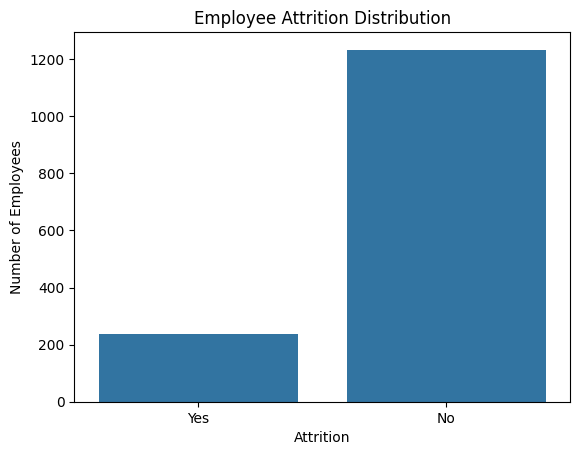

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Check attrition counts
print("Attrition Count:")
print(data["Attrition"].value_counts())

# Calculate attrition percentage
attrition_percentage = (
    data["Attrition"].value_counts(normalize=True) * 100
).round(2)

print("\nAttrition Percentage:")
print(attrition_percentage)

# Visualize attrition distribution
sns.countplot(data=data, x="Attrition")
plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")
plt.show()

**Department-wise attrition**

Department-wise employee attrition:


Attrition,No,Yes
Department,,
Human Resources,51,12
Research & Development,828,133
Sales,354,92



Department-wise attrition rate:


Attrition,Attrition_Rate_%
Department,
Human Resources,19.05
Research & Development,13.84
Sales,20.63


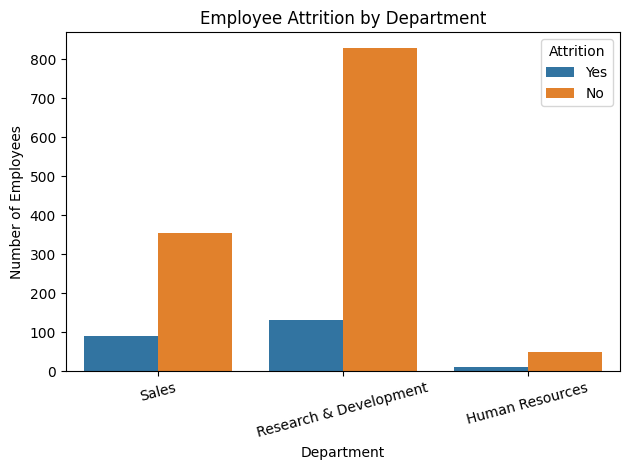

In [10]:
# Employee count and attrition by department
department_attrition = pd.crosstab(
    data["Department"],
    data["Attrition"]
)

print("Department-wise employee attrition:")
display(department_attrition)

# Calculate attrition rate for each department
department_attrition["Attrition_Rate_%"] = (
    department_attrition["Yes"]
    / department_attrition.sum(axis=1)
    * 100
).round(2)

print("\nDepartment-wise attrition rate:")
display(department_attrition[["Attrition_Rate_%"]])

# Visualize attrition by department
sns.countplot(
    data=data,
    x="Department",
    hue="Attrition"
)

plt.title("Employee Attrition by Department")
plt.xlabel("Department")
plt.ylabel("Number of Employees")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


**Overtime aur Attrition**

Overtime and Attrition Count:


Attrition,No,Yes
OverTime,,
No,944,110
Yes,289,127



Attrition Rate by Overtime (%):


,0
OverTime,
No,10.44
Yes,30.53


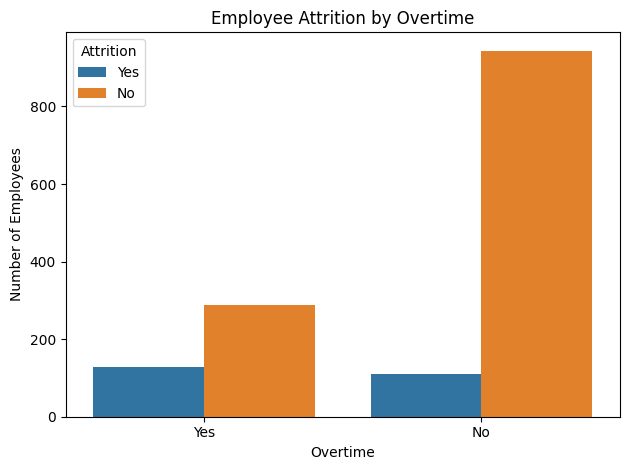

In [11]:
# Overtime vs Attrition
overtime_table = pd.crosstab(
    data["OverTime"],
    data["Attrition"]
)

print("Overtime and Attrition Count:")
display(overtime_table)

# Calculate attrition rate for each overtime group
overtime_rate = (
    overtime_table["Yes"]
    / overtime_table.sum(axis=1)
    * 100
).round(2)

print("\nAttrition Rate by Overtime (%):")
display(overtime_rate)

# Visualize overtime and attrition
sns.countplot(
    data=data,
    x="OverTime",
    hue="Attrition"
)

plt.title("Employee Attrition by Overtime")
plt.xlabel("Overtime")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()

**Job Satisfaction and Attrition**

Job Satisfaction vs Attrition:


Attrition,No,Yes
JobSatisfaction,,
1,223,66
2,234,46
3,369,73
4,407,52



Attrition Rate by Job Satisfaction:


Attrition,Attrition_Rate_%
JobSatisfaction,
1,22.84
2,16.43
3,16.52
4,11.33


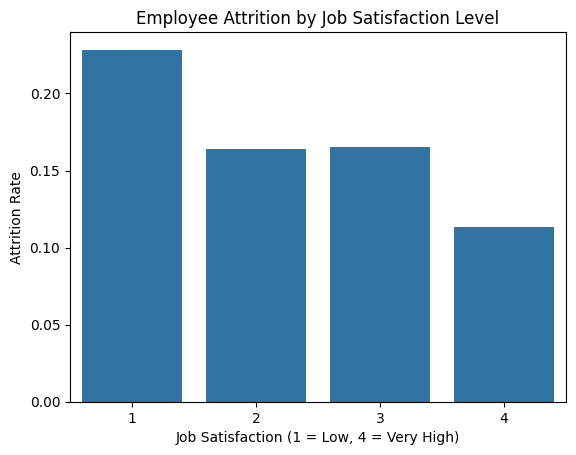

In [12]:
# Job Satisfaction vs Attrition
satisfaction_table = pd.crosstab(
    data["JobSatisfaction"],
    data["Attrition"]
)

print("Job Satisfaction vs Attrition:")
display(satisfaction_table)

# Calculate attrition rate by satisfaction level
satisfaction_table["Attrition_Rate_%"] = (
    satisfaction_table["Yes"]
    / satisfaction_table[["No", "Yes"]].sum(axis=1)
    * 100
).round(2)

print("\nAttrition Rate by Job Satisfaction:")
display(satisfaction_table[["Attrition_Rate_%"]])

# Visualize the relationship
sns.barplot(
    data=data,
    x="JobSatisfaction",
    y=data["Attrition"].eq("Yes").astype(int),
    errorbar=None
)

plt.title("Employee Attrition by Job Satisfaction Level")
plt.xlabel("Job Satisfaction (1 = Low, 4 = Very High)")
plt.ylabel("Attrition Rate")
plt.show()

## Key Findings

1. The overall employee attrition rate is 16.12%.
2. The Sales department has the highest attrition rate among the three departments at 20.63%.
3. Employees working overtime have a higher attrition rate (30.53%) than employees not working overtime (10.44%).
4. Employees with job satisfaction level 1 have an attrition rate of 22.84%, compared with 11.33% for level 4.

## Conclusion

The analysis identifies differences in employee attrition across departments, overtime status, and job satisfaction levels. These findings can help guide further investigation into workforce retention patterns. The observed relationships do not establish causation.